# Team 17 Four Module Hotel Review Demonstration
**Tanay Mohta and Aditya Rawat**

This notebook demonstrates the current **SentiWordNet** and independent **VADER–TextBlob Hybrid** using four labeled modules. Each module displays its real input, processing output and the object passed to the next module. Tables and traces are computed by the project code, not hardcoded predictions.

**Google Colab:** open this `.ipynb` through **File → Upload notebook**, then choose **Runtime → Run all**. When prompted, upload **Team_17_Colab_Project.zip**. No GPU, API key or model training is needed. An internet connection is needed for the first dependency installation. Existing example outputs are already saved in this notebook.

**Module 1** Preprocessing and validation → **Module 2** Lexical and grammatical analysis → **Module 3** Semantic attachment and lexical evidence → **Module 4** Adjustments and final records.

The two paths remain independent. The SentiWordNet AST is never supplied to the hybrid. Some internal helpers combine multiple tasks; the notebook exposes their actual records rather than claiming identical internal parsers.

## Setup
This cell locates the local project or extracts the supplied portable bundle in Colab. It installs only missing pinned sentiment dependencies. No private review annotations or credentials are required.

In [1]:
from pathlib import Path
import sys, subprocess, importlib.util, importlib.metadata, zipfile
IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB:
    PROJECT = Path("/content/team17_module_demo")
    if not (PROJECT / "hotel_compiler").exists():
        from google.colab import files
        print("Upload Team_17_Colab_Project.zip")
        uploaded = files.upload()
        bundle = next((Path(name) for name in uploaded if name.endswith('.zip')), None)
        if bundle is None: raise ValueError("Upload the project ZIP supplied with this notebook.")
        PROJECT.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(bundle) as archive:
            for name in archive.namelist():
                target = (PROJECT / name).resolve()
                if not target.is_relative_to(PROJECT.resolve()):
                    raise ValueError("Unsafe archive path")
            archive.extractall(PROJECT)
else:
    PROJECT = Path.cwd()
    if not (PROJECT / "hotel_compiler").exists():
        raise RuntimeError("Run locally from the project root, or open this notebook in Google Colab.")
sys.path.insert(0, str(PROJECT))
requirements = {'vaderSentiment':'vaderSentiment==3.3.2', 'textblob':'textblob==0.19.0', 'nltk':'nltk==3.10.3'}
missing = [package for module,package in requirements.items()
    if importlib.util.find_spec(module) is None or importlib.metadata.version(module)!=package.split('==')[1]]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print("Project code ready. Local processing only; no new model is trained.")

Project code ready. Local processing only; no new model is trained.


In [2]:
from dataclasses import asdict, replace
from html import escape
from math import fsum
import base64, csv, io
from hotel_compiler.compiler_profiles import compiler_profile
from hotel_compiler.lexer import tokenize
from hotel_compiler.parser import parse
from hotel_compiler.semantics import analyze_semantics
from hotel_compiler.sentiwordnet import evaluate, load_synsets
from hotel_compiler.vocabulary import load_vocabulary
from hotel_compiler.hybrid import HybridEngine, HybridAspect, HybridAnalysis, analyze_hybrid_review
from hotel_compiler.hybrid_nlp import analyze_language, domain_adjustment
from hotel_compiler.models import AnalysisResult
from hotel_compiler.pipeline import analyze_review
from hotel_compiler.sentiment_policy import DEFAULT_POLICY, overall_polarity
ENGINE = HybridEngine()

def emit(data):
    if '_capture_output' in globals():
        _capture_output(data)
    else:
        from IPython.display import display
        display(data, raw=True)

def table(title, rows):
    rows = list(rows)
    if not rows:
        emit({'text/html': '<h4>'+escape(title)+'</h4><p>No records or diagnostics.</p>'})
        return
    columns = list(dict.fromkeys(k for row in rows for k in row))
    html = '<h4>'+escape(title)+'</h4><div style="overflow-x:auto"><table style="border-collapse:collapse;font-size:13px"><thead><tr>'
    html += ''.join('<th style="border:1px solid #bbb;padding:6px;text-align:left">'+escape(k)+'</th>' for k in columns)+'</tr></thead><tbody>'
    for row in rows:
        html += '<tr>'+''.join('<td style="border:1px solid #bbb;padding:6px;vertical-align:top">'+escape(str(row.get(k,'')))+'</td>' for k in columns)+'</tr>'
    emit({'text/html':html+'</tbody></table></div>'})

def diagram(name):
    options = [PROJECT/'diagrams'/f'{name}.png', PROJECT/'output/paper/assets'/f'{name}.png']
    path = next(p for p in options if p.is_file())
    emit({'image/png':base64.b64encode(path.read_bytes()).decode('ascii')})

print('Components:', ENGINE.versions)

Components: {'vaderSentiment': '3.3.2', 'textblob': '0.19.0', 'nltk': '3.10.3'}


## Choose the input review
Edit `REVIEW_TEXT`, then rerun this cell and Modules 1–4. The default is an **authored teaching example**, not a claimed real dataset review.

Other useful inputs: `The air conditioning wasn't working.` (explicit failure rule), or `The room was clean, but the location was convenient.` (Partial because Location is outside scope).

In [3]:
REVIEW_ID = "FACULTY-DEMO-1"
REVIEW_TEXT = "The room was clean but the staff were rude."
# Optional real data instead: uncomment these lines to use an actual cleaned review.
# with (PROJECT/'dataset/booking_italy_cleaned_demo_500.csv').open(encoding='utf-8-sig', newline='') as f:
#     row = next(csv.DictReader(f))
# REVIEW_ID, REVIEW_TEXT = row['sr.no'], row['review']
table('Selected input', [{'review_id': REVIEW_ID, 'review': REVIEW_TEXT}])

review_id,review
FACULTY-DEMO-1,The room was clean but the staff were rude.


## Module 1 Preprocessing and validation
**Input:** review ID and original review text. **Processing:** validate types, nonblank text and length; retain original case, punctuation, negation and character positions. **Output to Module 2:** `M1`, containing validated original text and identity.

Normalization and contraction expansion happen in source-mapped working copies in the corresponding front ends. Global lowercasing or deletion of punctuation is avoided. For CSV input, field decoding/row validation is performed by `csv_input.py`; this cell demonstrates a single validated review.

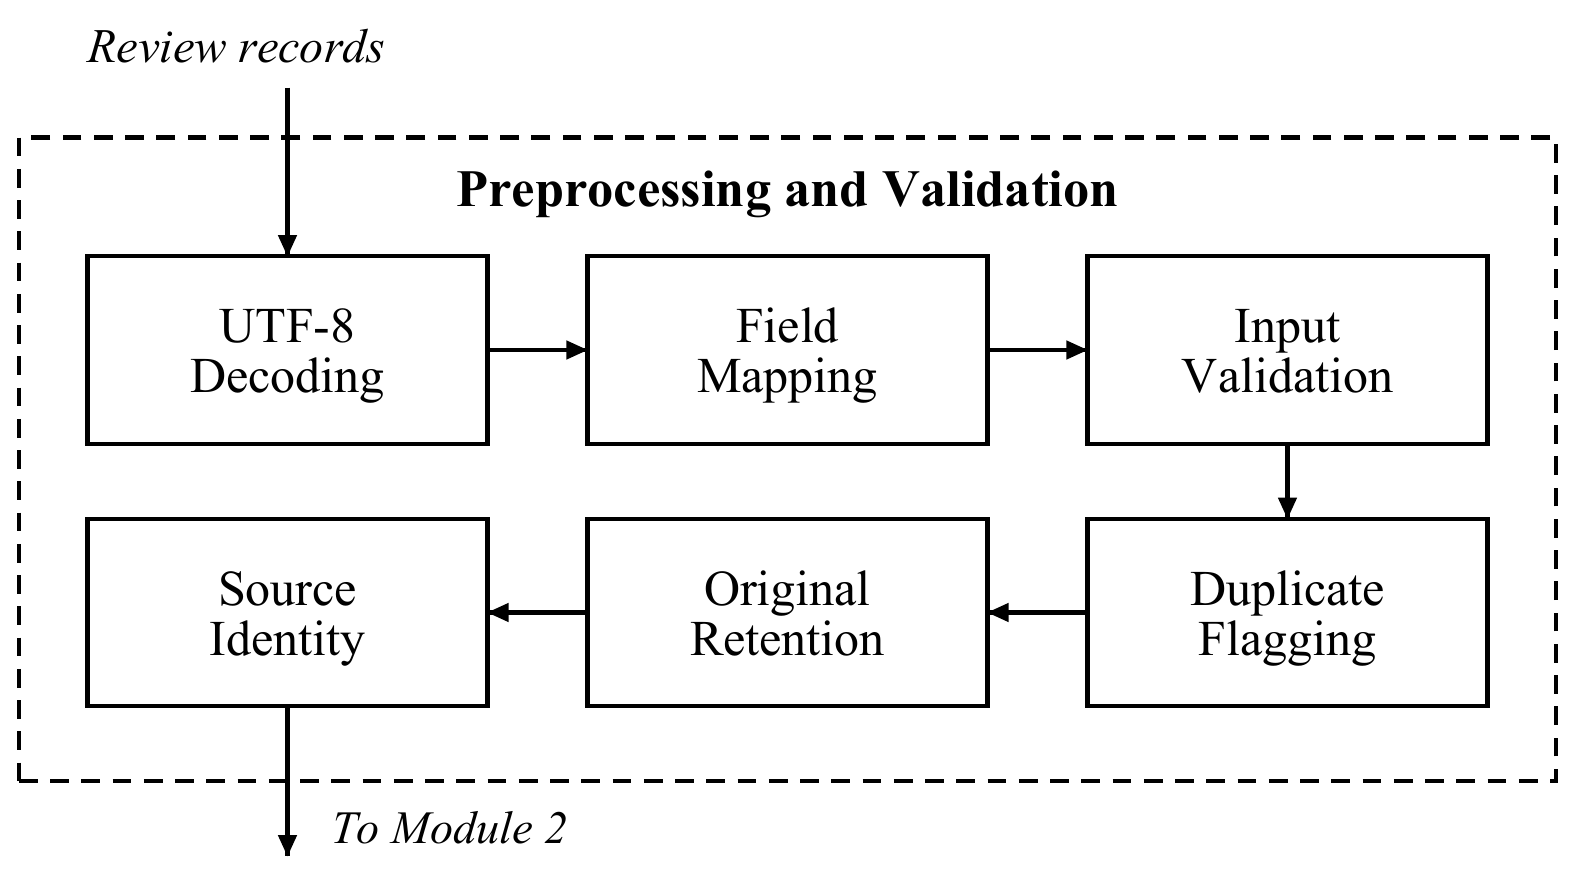

review_id,raw_text
FACULTY-DEMO-1,The room was clean but the staff were rude.


review_id,text,characters
FACULTY-DEMO-1,The room was clean but the staff were rude.,43


In [4]:
diagram('module1_preprocessing')
table('Module 1 INPUT', [{'review_id': REVIEW_ID, 'raw_text': REVIEW_TEXT}])
if not isinstance(REVIEW_TEXT,str) or not isinstance(REVIEW_ID,str) or not REVIEW_ID.strip():
    raise ValueError('Review text and nonblank ID must be strings.')
if not REVIEW_TEXT.strip(): raise ValueError('Review is blank; no analysis should be invented.')
if len(REVIEW_TEXT)>10000: raise ValueError('Maximum review length is 10,000 characters.')
M1 = {'review_id':REVIEW_ID, 'text':REVIEW_TEXT, 'characters':len(REVIEW_TEXT)}
table('Module 1 OUTPUT → Module 2', [M1])

## Module 2 Lexical and grammatical analysis
**Input:** `M1['text']`. **SentiWordNet processing:** longest-match tokens, controlled predictive grammar and bounded recovery. **Hybrid processing:** Pattern POS/phrase chunks plus project segmentation, target attachment and limited reference rules.

**Output to Module 3:** SentiWordNet tokens/AST and diagnostics; independently generated Hybrid grammatical candidates and linguistic evidence. Hybrid's `analyze_language` helper includes category lookup/attachment while generating candidates, so those records already carry proposed categories. It never consumes the SentiWordNet AST.

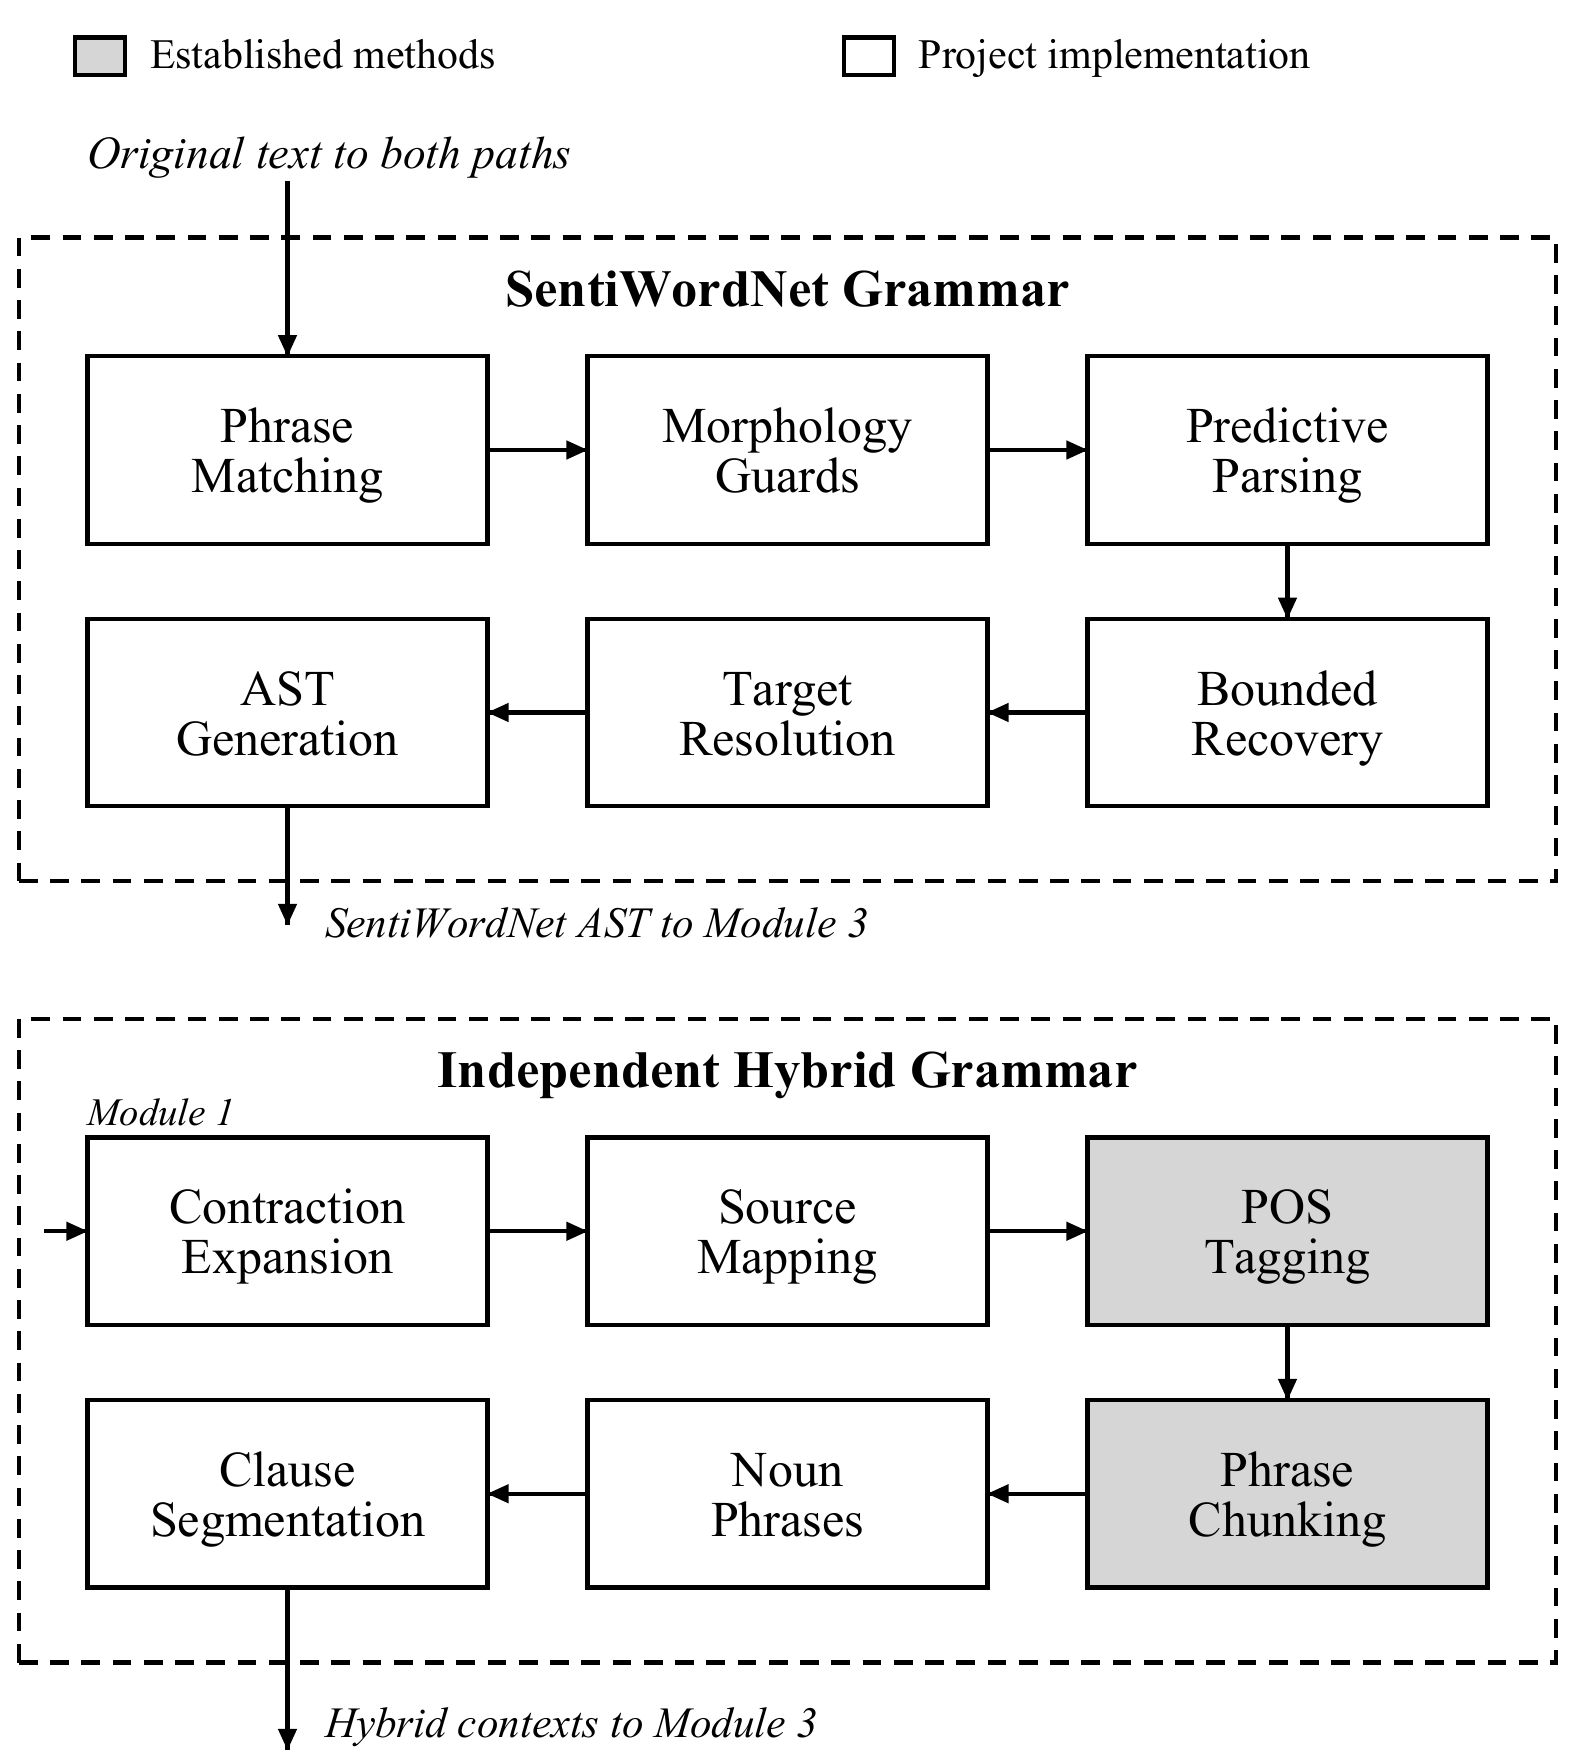

review_id,text,characters
FACULTY-DEMO-1,The room was clean but the staff were rude.,43


text,type,canonical,start,end
The,DETERMINER,the,0,3
room,ASPECT,room,4,8
was,COPULA,was,9,12
clean,OPINION,clean,13,18
but,CONNECTOR,but,19,22
the,DETERMINER,the,23,26
staff,ASPECT,staff,27,32
were,COPULA,were,33,37
rude,OPINION,rude,38,42
.,END,.,42,43


subject,opinion,negated,modifier,grammar,start,end
room,clean,False,,subject_predicate,0,18
staff,rude,False,,subject_predicate,23,42


text,pos,chunk,preposition,start,end,sentence
The,DT,B-NP,O,0,3,0
room,NN,I-NP,O,4,8,0
was,VBD,B-VP,O,9,12,0
clean,JJ,B-ADJP,O,13,18,0
but,CC,O,O,19,22,0
the,DT,B-NP,O,23,26,0
staff,NN,I-NP,O,27,32,0
were,VBD,B-VP,O,33,37,0
rude,JJ,B-ADJP,O,38,42,0
.,.,O,O,42,43,0


text,start,end
The room,0,8
the staff,23,32


text,start,end,sentence,candidate_indexes
The room was clean,0,18,0,[0]
the staff were rude.,23,43,0,[1]


category,aspect,context,start,end,aspect_start,aspect_end,pattern,inherited
Room,room,The room was clean,0,18,4,8,aspect_predicate,False
Staff,staff,the staff were rude.,23,43,27,32,aspect_predicate,False


Module 2 diagnostics No records or diagnostics.

In [5]:
diagram('module2_grammar')
table('Module 2 INPUT from Module 1', [M1])
with compiler_profile('expanded'):
    sw_tokens = tokenize(M1['text'])
    sw_ast, sw_syntax_diagnostics = parse(sw_tokens)
hy_language = analyze_language(M1['text'], ENGINE.parser, ENGINE.has_lexical)
M2 = {'swn_tokens':sw_tokens, 'swn_ast':sw_ast, 'swn_diagnostics':sw_syntax_diagnostics,
      'hybrid_language':hy_language}
table('SentiWordNet tokens', [{'text':t.text,'type':t.kind,'canonical':t.value,'start':t.start,'end':t.end} for t in sw_tokens])
table('SentiWordNet AST → Module 3', [{'subject':c.subject.text if c.subject else '(inherited)',
    'opinion':c.opinion.text,'negated':c.negation is not None,'modifier':c.intensifier.text if c.intensifier else '',
    'grammar':c.form,'start':c.start,'end':c.end} for c in sw_ast.clauses])
table('Hybrid POS and chunks', [asdict(t) for t in hy_language.tokens])
table('Hybrid noun phrases', hy_language.noun_phrases)
table('Hybrid segments', hy_language.segments)
table('Hybrid candidates → Module 3', [asdict(c) for c in hy_language.candidates])
table('Module 2 diagnostics', [asdict(d) for d in (*sw_syntax_diagnostics,*hy_language.diagnostics)])

## Module 3 Semantic attachment and lexical evidence
**Input:** Module 2 AST and independent Hybrid candidates. **SentiWordNet processing:** category/issue interpretation, compatibility checks and selected native sense lookup; expose P, N, objective value `1-P-N` and lexical value `P-N`. **Hybrid processing:** score candidate contexts with VADER and TextBlob, retain guarded scoring-copy evidence, and fuse components with lexical evidence.

**Output to Module 4:** semantic records/native lexical evidence and Hybrid candidates paired with their pre-domain scoring evidence. Domain/intensity/negation adjustments for SentiWordNet and Hybrid context overrides are explained in Module 4. Component tools already apply their own internal valence rules; their raw outputs are not raw dictionary entries.

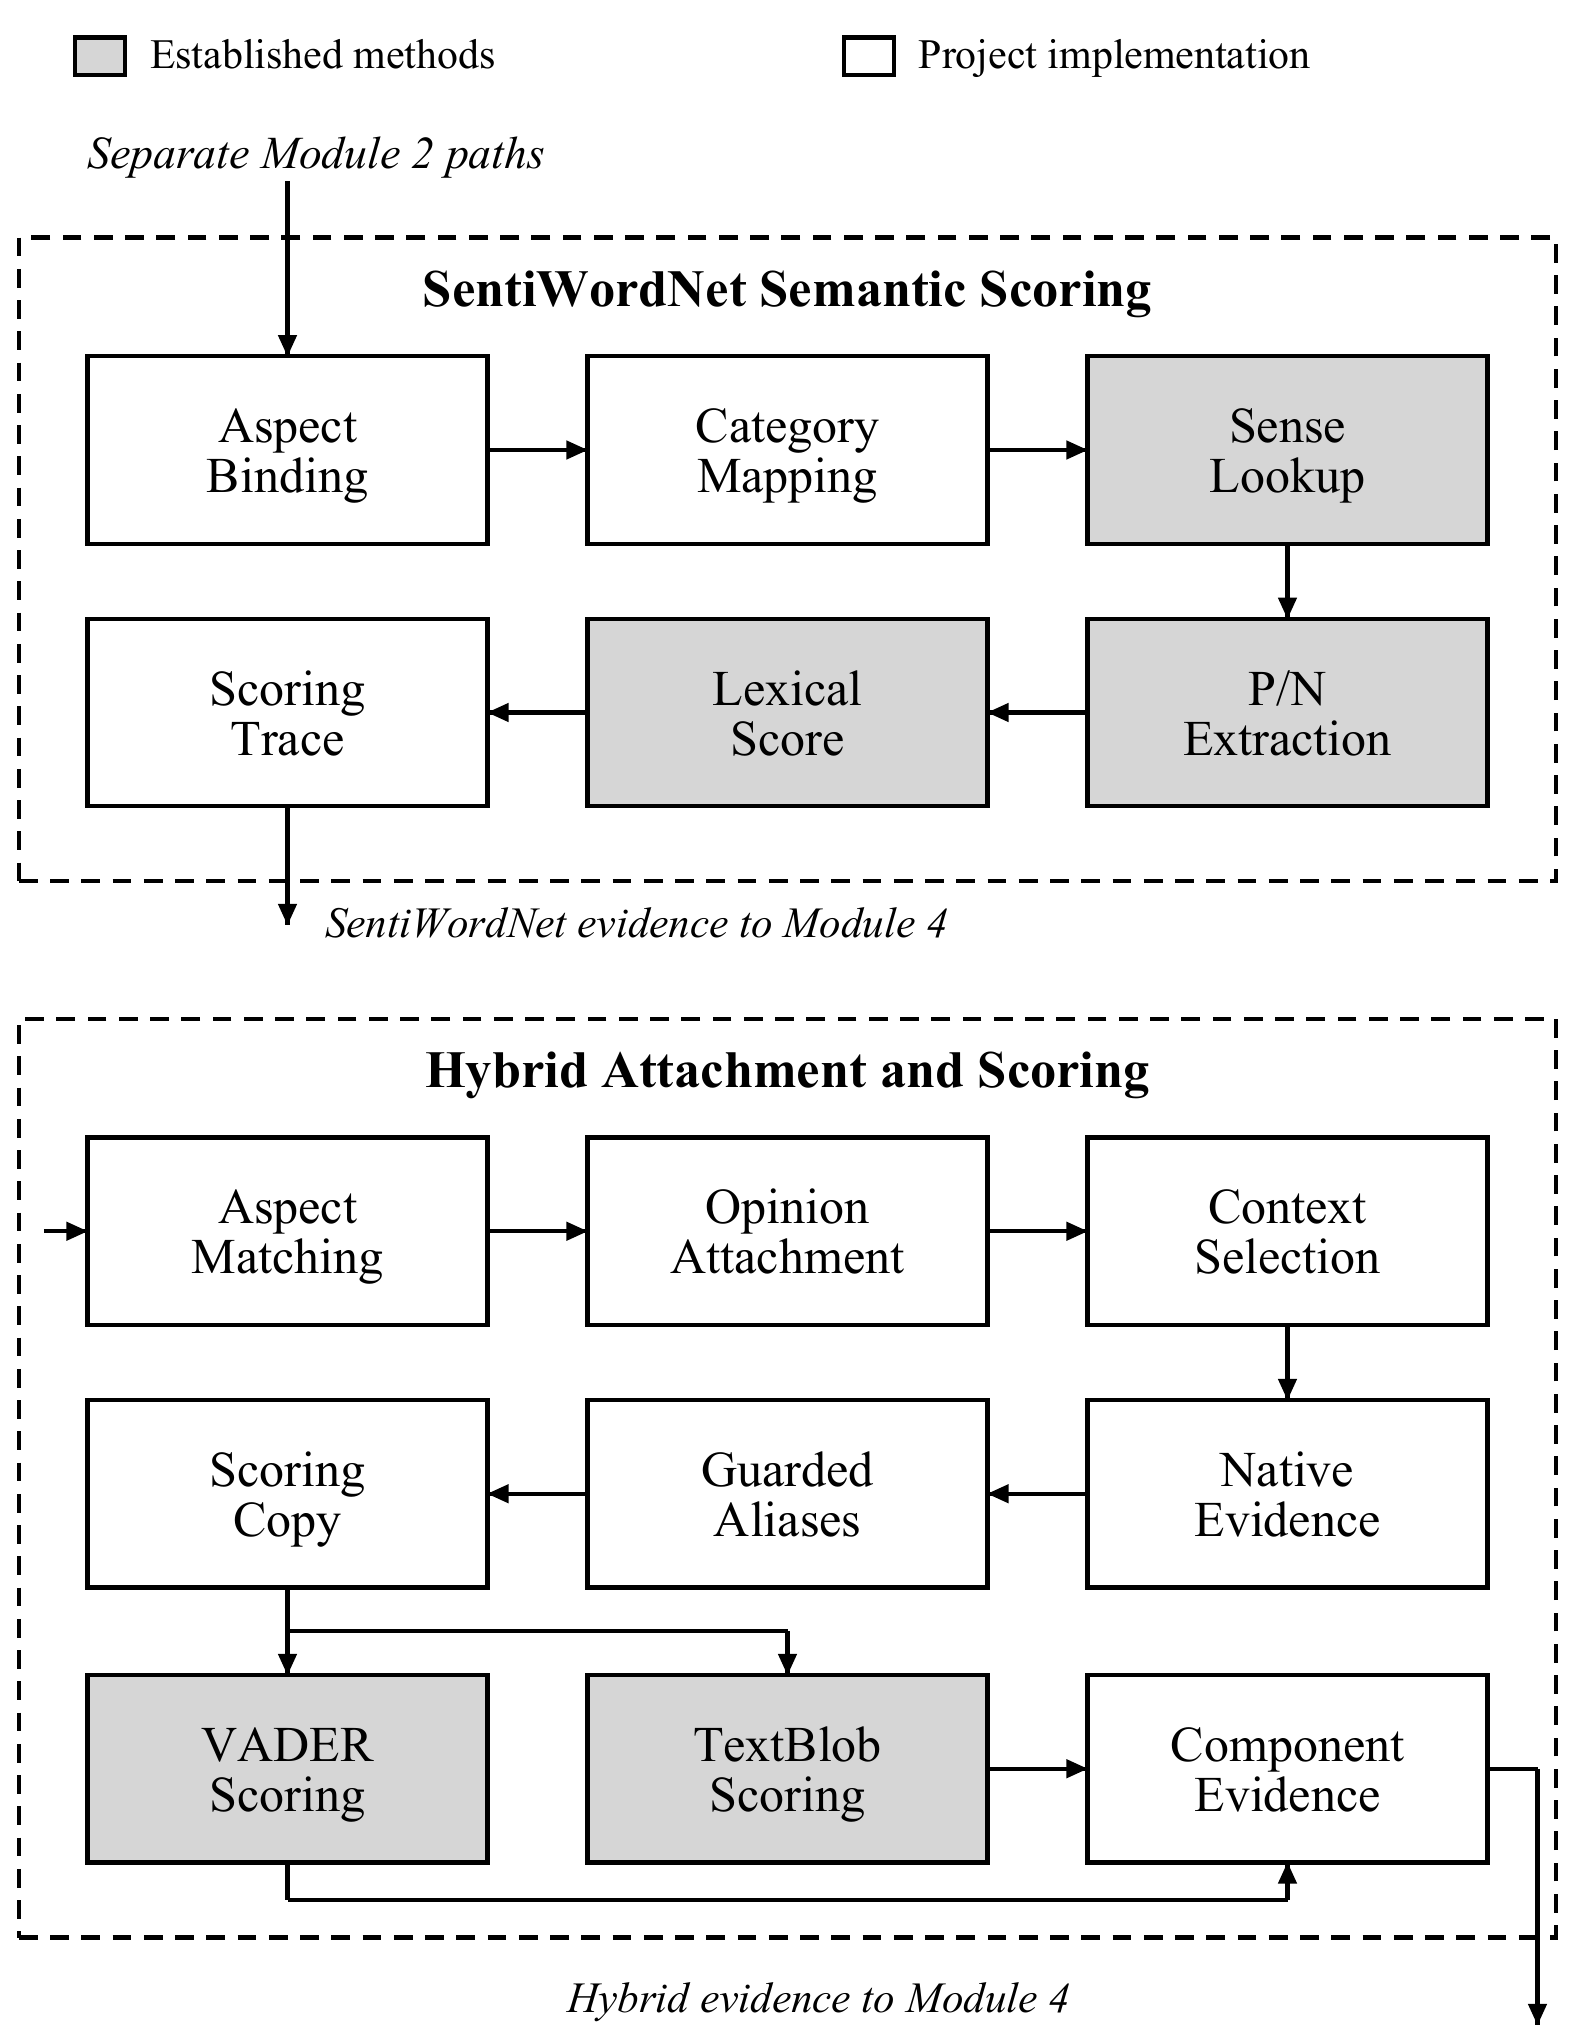

path,input,count
SentiWordNet,AST clauses,2
Hybrid,Independent attached contexts,2


category,issue,aspect,opinion,synset,P,N,objective,lexical_P_minus_N
Room,Cleanliness,room,clean,a:00417413,0.5,0.375,0.125,0.125
Staff,Friendliness,staff,rude,a:00641944,0.0,0.625,0.375,-0.625


category,aspect,context,VADER,TextBlob,subjectivity,VADER_evidence,TextBlob_evidence,fusion,rule,status
Room,room,The room was clean,0.4019,0.3666666666666667,0.7000000000000001,True,True,0.384283,weighted_both,scored
Staff,staff,the staff were rude.,-0.4588,-0.3,0.6,True,True,-0.3794,weighted_both,scored


Hybrid scoring-copy transformations No records or diagnostics.

Module 3 semantic diagnostics No records or diagnostics.

In [6]:
diagram('module3_scoring')
table('Module 3 INPUT handoff', [{'path':'SentiWordNet','input':'AST clauses','count':len(M2['swn_ast'].clauses)},
    {'path':'Hybrid','input':'Independent attached contexts','count':len(M2['hybrid_language'].candidates)}])
with compiler_profile('expanded'):
    sw_semantics, sw_semantic_diagnostics = analyze_semantics(M2['swn_ast'], M1['text'])
    vocab, senses = load_vocabulary(), load_synsets()
    sw_native = []
    for record in sw_semantics:
        spec = vocab['opinions'][record.opinion_term]
        context = spec.get('category_senses',{}).get(record.category,{})
        sid = context.get('synset',spec['synset']); sense = senses[sid]
        sw_native.append({'category':record.category,'issue':record.issue,'aspect':record.aspect_term,
            'opinion':record.opinion_expression,'synset':sid,'P':sense.positive,'N':sense.negative,
            'objective':1-sense.positive-sense.negative,'lexical_P_minus_N':sense.positive-sense.negative})
hy_lexical = [(candidate,ENGINE.score_text(candidate.context,category=candidate.category))
              for candidate in M2['hybrid_language'].candidates]
M3 = {'swn_semantics':sw_semantics, 'swn_native':sw_native, 'swn_diagnostics':sw_semantic_diagnostics,
      'hybrid_lexical':hy_lexical}
table('SentiWordNet semantic and native evidence → Module 4', sw_native)
table('Hybrid lexical evidence → Module 4', [{'category':c.category,'aspect':c.aspect,'context':c.context,
    'VADER':e.vader_compound,'TextBlob':e.textblob_polarity,'subjectivity':e.textblob_subjectivity,
    'VADER_evidence':e.vader_has_evidence,'TextBlob_evidence':e.textblob_has_evidence,
    'fusion':e.lexical_fusion_score,'rule':e.fusion_rule,'status':e.status} for c,e in hy_lexical])
table('Hybrid scoring-copy transformations', [{'context':c.context,'normalization':e.vocabulary_normalization}
    for c,e in hy_lexical if e.vocabulary_normalization])
table('Module 3 semantic diagnostics', [asdict(d) for d in sw_semantic_diagnostics])

## Module 4 Adjustments and final records
**Input:** `M3` semantic/native evidence and Hybrid lexical contexts. **SentiWordNet:** apply configured domain value × intensity × negation, clip to [-1,1], then assign labels. **Hybrid:** apply unambiguous configured context rules to the retained fusion evidence, without applying the SentiWordNet negation multiplier again.

**Final output:** per-aspect records, five descriptive strength bands, per-review mean, Mixed where polarities coexist, processing status and diagnostics. Complete is a heuristic, not guaranteed correctness. SentiWordNet can average retained scored opinions on Partial results; Hybrid's aspect mean requires every extracted context to be scored. Whole-review lexical sentiment remains separate.

The notebook assembles final records from the preceding modules and checks them against the public production analysis APIs. No predictions or example scores are hardcoded.

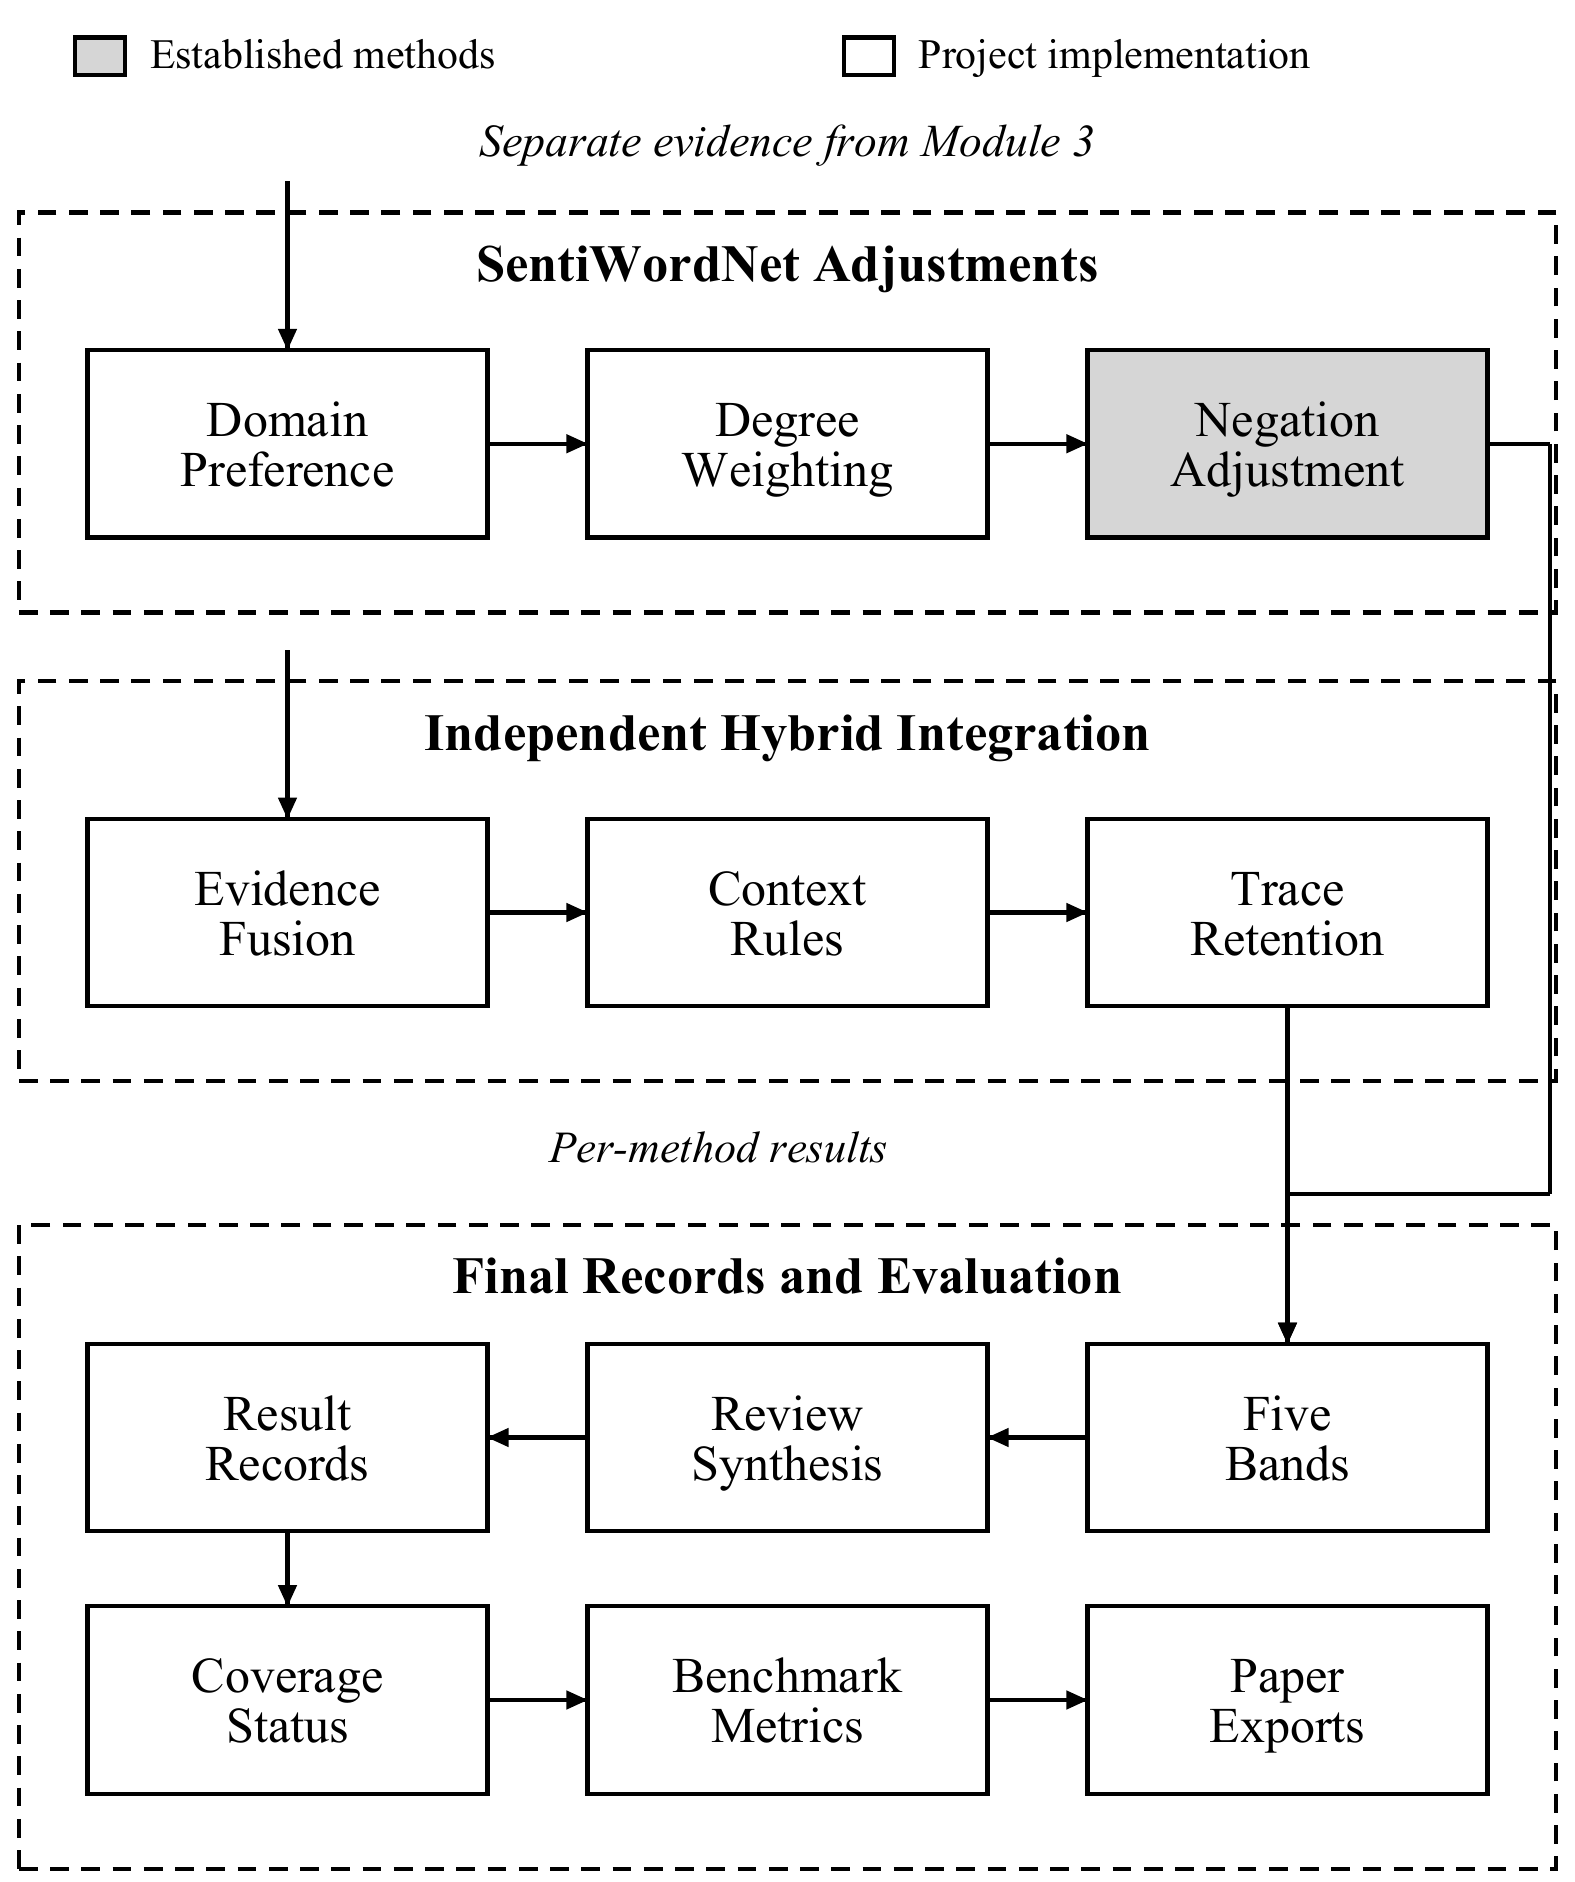

SentiWordNet_semantic_records,Hybrid_lexical_contexts
2,2


category,issue,opinion,L,D,intensity,negation,score,polarity,strength
Room,Cleanliness,clean,0.125,0.125,1.0,1,0.125,Positive,Weak Positive
Staff,Friendliness,rude,-0.625,-0.625,1.0,1,-0.625,Negative,Strong Negative


category,aspect,context,fusion_before_rule,context_rule,final_score,polarity,strength
Room,room,The room was clean,0.384283,None,0.384283,Positive,Weak Positive
Staff,staff,the staff were rude.,-0.3794,None,-0.3794,Negative,Weak Negative


method,status,overall,aspect_mean,whole_text_score
SentiWordNet,complete,Mixed,-0.25,Not substituted for aspects
Hybrid,complete,Mixed,0.002441,-0.226033


Final diagnostics No records or diagnostics.

PASS: module-wise assembled outputs exactly match both production analysis APIs.


In [7]:
diagram('module4_synthesis')
table('Module 4 INPUT from Module 3', [{'SentiWordNet_semantic_records':len(M3['swn_semantics']),
    'Hybrid_lexical_contexts':len(M3['hybrid_lexical'])}])
with compiler_profile('expanded'):
    sw_records = tuple(evaluate(r,M1['review_id']) for r in M3['swn_semantics'])
sw_diags = (*M2['swn_diagnostics'],*M3['swn_diagnostics'])
sw_status = 'complete' if sw_records and not sw_diags else 'partial' if sw_records else 'unsupported'
SWN = AnalysisResult(M1['review_id'],M1['text'],sw_status,overall_polarity(r.polarity for r in sw_records),
    sw_records,sw_diags,M2['swn_tokens'],M2['swn_ast'],M3['swn_semantics'],compiler_profile='expanded')
hy_records=[]
for candidate,evidence in M3['hybrid_lexical']:
    rule = domain_adjustment(candidate.category,candidate.context)
    if rule and evidence.status!='processing_error':
        score=rule['score']
        evidence=replace(evidence,score=score,polarity=DEFAULT_POLICY.polarity(score),
            strength=DEFAULT_POLICY.strength(score),status='scored',fusion_rule='contextual_domain_rule',
            domain_rule_id=rule['rule_id'],domain_matched_text=rule['matched'])
    hy_records.append(HybridAspect(candidate.category,evidence.domain_rule_id or 'General',candidate.context,
        candidate.start,candidate.end,evidence,aspect_term=candidate.aspect,aspect_start=candidate.aspect_start,
        aspect_end=candidate.aspect_end,grammar_pattern=candidate.pattern,inherited=candidate.inherited))
from hotel_compiler.hybrid_nlp import NLPDiagnostic
hy_diags=list(M2['hybrid_language'].diagnostics)
for r in hy_records:
    if r.evidence.status!='scored':
        hy_diags.append(NLPDiagnostic(r.evidence.status.upper(),'Attached aspect context has no usable sentiment score.',r.start,r.end,'hybrid_sentiment'))
hy_status = ('processing_error' if any(r.evidence.status=='processing_error' for r in hy_records)
    else 'complete' if hy_records and not hy_diags else 'partial' if any(r.score is not None for r in hy_records) else 'unsupported')
HYBRID=HybridAnalysis(M1['review_id'],hy_status,tuple(hy_records),ENGINE.score_text(M1['text']),M1['text'],M2['hybrid_language'],tuple(hy_diags))
M4={'SentiWordNet':SWN,'Hybrid':HYBRID}
table('SentiWordNet adjustments and final IR', [{'category':r.category,'issue':r.issue,'opinion':r.opinion_expression,
    'L':r.evidence.lexical_score,'D':r.evidence.domain_score,'intensity':r.evidence.intensity_multiplier,
    'negation':r.evidence.negation_multiplier,'score':r.score,'polarity':r.polarity,'strength':r.strength} for r in SWN.records])
table('Hybrid adjustments and final IR', [{'category':r.category,'aspect':r.aspect_term,'context':r.opinion_expression,
    'fusion_before_rule':r.evidence.lexical_fusion_score,'context_rule':r.evidence.domain_rule_id,
    'final_score':r.score,'polarity':r.polarity,'strength':r.evidence.strength} for r in HYBRID.records])
table('FINAL REVIEW OUTPUT', [{'method':'SentiWordNet','status':SWN.status,'overall':SWN.overall,'aspect_mean':SWN.review_score,
    'whole_text_score':'Not substituted for aspects'}, {'method':'Hybrid','status':HYBRID.aspect_analysis_status,
    'overall':HYBRID.overall,'aspect_mean':HYBRID.aspect_mean_score,'whole_text_score':HYBRID.whole_text.score}])
table('Final diagnostics', [dict(method='SentiWordNet',**asdict(d)) for d in SWN.diagnostics]
    + [dict(method='Hybrid',**asdict(d)) for d in HYBRID.diagnostics])
assert SWN.to_dict(include_trace=True)==analyze_review(M1['text'],M1['review_id'],profile='expanded').to_dict(include_trace=True)
assert HYBRID.to_dict()==analyze_hybrid_review(M1['text'],M1['review_id'],engine=ENGINE).to_dict()
print('PASS: module-wise assembled outputs exactly match both production analysis APIs.')

## Module handoff summary
| Label | Receives | Sends |
|---|---|---|
| Module 1 Preprocessing and validation | Review ID and original review | Validated original text and identity (`M1`) |
| Module 2 Lexical and grammatical analysis | `M1` original text independently in both paths | Tokens/AST/diagnostics and independent Hybrid candidates (`M2`) |
| Module 3 Semantic attachment and lexical evidence | `M2` structures and candidates | Semantic records, native P/N and pre-domain Hybrid fusion evidence (`M3`) |
| Module 4 Adjustments and final records | `M3` evidence plus retained source diagnostics | Adjusted scores, bands, aspect IR, review summaries and status (`M4`) |

**Useful demonstrations:** the default example retains opposing Room/Staff opinions as Mixed. The air-conditioning example shows an explicit hybrid domain rule. The Location example shows why a useful result can be Partial. Edit the input and rerun Modules 1–4; outputs refresh from actual code.

**Scope:** six categories; no LLM calls, SQL or newly trained model. Five bands are descriptive rather than validated five-class accuracy. This notebook demonstrates processing; it is not the full paper's annotated benchmark evaluation.